# 04 — Model Comparison (Week 5)
**Goal:** try a **Decision Tree** and a **Random Forest**, compare their test R² against the Week 4 Linear Regression baseline (**R² = 0.779**), and write down how each model behaves.

Everything else stays fixed so the comparison is fair:
* same cleaned data (`cleaned_sfr.csv` from `02_preprocessing_simple.ipynb`)
* same `prepare()` (median fill, encoding, scaling learned from train only)
* same split: train May 2025 – Apr 2026, test May 2026
* same target: log(ClosePrice), converted back to dollars for R²

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

pd.set_option("display.float_format", "{:,.3f}".format)

TARGET = "ClosePrice"
NUMERIC = ["LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
           "YearBuilt", "GarageSpaces", "Stories", "Latitude", "Longitude"]
BINARY = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]

## 1. Load data and preprocess (same as Weeks 3–4)

In [2]:
df = pd.read_csv("cleaned_sfr.csv", parse_dates=["CloseDate"], dtype={"PostalCode": str})
train = df[df["Split"] == "train"].drop(columns="Split")
test = df[df["Split"] == "test"].drop(columns="Split")
print(f"Train: {train['CloseDate'].min():%b %Y} – {train['CloseDate'].max():%b %Y}, {len(train):,} sales")
print(f"Test:  {test['CloseDate'].min():%b %Y}, {len(test):,} sales")

Train: May 2025 – Apr 2026, 106,696 sales
Test:  May 2026, 11,991 sales


`prepare()` and `time_split()` are copied unchanged from `02_preprocessing_simple.ipynb`.

In [3]:
ZIP_SMOOTHING = 20   # a ZIP needs ~20 sales before its own average outweighs the statewide one


def prepare(train, test):
    """Learn medians, ZIP prices, county columns and scaling from `train`; apply them to both."""
    train, test = train.copy(), test.copy()

    # 1) median fill + "was missing" flags
    medians = train[NUMERIC].median()
    for col in NUMERIC:
        if train[col].isna().any():
            train[f"{col}_missing"] = train[col].isna().astype(int)
            test[f"{col}_missing"] = test[col].isna().astype(int)
    train[NUMERIC] = train[NUMERIC].fillna(medians)
    test[NUMERIC] = test[NUMERIC].fillna(medians)

    # 2) log the skewed columns
    for col in ["LivingArea", "LotSizeSquareFeet"]:
        train[col], test[col] = np.log1p(train[col]), np.log1p(test[col])

    # 3) ZIP -> smoothed average log price (training rows only)
    log_price = np.log(train[TARGET])
    overall = log_price.mean()
    stats = log_price.groupby(train["PostalCode"]).agg(["mean", "count"])
    zip_value = (stats["count"] * stats["mean"] + ZIP_SMOOTHING * overall) / (stats["count"] + ZIP_SMOOTHING)
    train["ZipPrice"] = train["PostalCode"].map(zip_value)
    test["ZipPrice"] = test["PostalCode"].map(zip_value).fillna(overall)   # unseen ZIP -> statewide average

    # 4) county one-hot; test gets exactly the training columns (unseen county -> all zeros)
    X_train = pd.get_dummies(train.drop(columns=["ListingKey", "CloseDate", TARGET, "PostalCode"]),
                             columns=["CountyOrParish"], dtype=int)
    X_test = pd.get_dummies(test.drop(columns=["ListingKey", "CloseDate", TARGET, "PostalCode"]),
                            columns=["CountyOrParish"], dtype=int).reindex(columns=X_train.columns, fill_value=0)

    # 5) standardize the continuous columns
    scale_cols = NUMERIC + ["ZipPrice"]
    scaler = StandardScaler().fit(X_train[scale_cols])
    X_train[scale_cols] = scaler.transform(X_train[scale_cols])
    X_test[scale_cols] = scaler.transform(X_test[scale_cols])

    return X_train, X_test, np.log(train[TARGET]), test[TARGET]


def time_split(df, test_month, months_back):
    """Test = one calendar month. Train = the `months_back` months right before it."""
    month = df["CloseDate"].dt.to_period("M")
    test_month = pd.Period(test_month, "M")
    train = df[(month >= test_month - months_back) & (month < test_month)]
    test = df[month == test_month]
    return train, test

In [4]:
X_train, X_test, y_train, y_test = prepare(train, test)
print(f"X_train {X_train.shape}, X_test {X_test.shape}")


def evaluate(name, model, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test):
    """Fit on log price; report R² in dollars on train and test, plus fit time."""
    start = time.time()
    model.fit(X_tr, y_tr)
    seconds = time.time() - start
    test_pred = np.exp(model.predict(X_te))
    return {"model": name,
            "train_R2": r2_score(np.exp(y_tr), np.exp(model.predict(X_tr))),
            "test_R2": r2_score(y_te, test_pred),
            "median_pct_error": np.median(np.abs(test_pred - y_te) / y_te),
            "fit_seconds": seconds}, test_pred

X_train (106696, 77), X_test (11991, 77)


## 2. Decision Tree
A decision tree asks a chain of yes/no questions ("ZipPrice above X? LivingArea above Y?") and predicts the average price of the training homes that end up in the same leaf.

Its one key setting is **`max_depth`**, the number of questions it may ask:
* too shallow → too few groups, so it **underfits** (both scores low)
* too deep → each leaf holds a handful of homes, so it **memorizes** training prices (train R² near 1, test R² drops)

### Choosing the depth without peeking at May
Same idea as choosing X in Week 3: use **April 2026 as a practice test month**, train on the 12 months before it, and pick the depth that scores best there.

In [5]:
practice_train, practice = time_split(df.drop(columns="Split"), "2026-04", 12)
Xp_train, Xp_test, yp_train, yp_test = prepare(practice_train, practice)

rows = []
for depth in [4, 6, 8, 10, 12, 15, 20, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(Xp_train, yp_train)
    rows.append({"max_depth": "None (no limit)" if depth is None else depth,
                 "train_R2": r2_score(np.exp(yp_train), np.exp(tree.predict(Xp_train))),
                 "practice_R2": r2_score(yp_test, np.exp(tree.predict(Xp_test))),
                 "leaves": tree.get_n_leaves()})
depth_table = pd.DataFrame(rows)
depth_table

,max_depth,train_R2,practice_R2,leaves
0,4,0.634,0.600,16
1,6,0.767,0.740,64
2,8,0.822,0.789,256
3,10,0.866,0.777,954
4,12,0.909,0.746,3026
5,15,0.960,0.720,11213
6,20,0.992,0.706,41602
7,None (no limit),1.000,0.700,103028


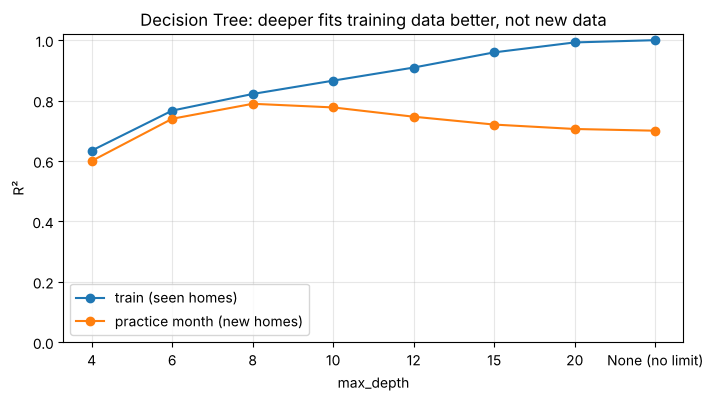

Chosen max_depth = 8


In [6]:
labels = depth_table["max_depth"].astype(str)
plt.figure(figsize=(8, 4))
plt.plot(labels, depth_table["train_R2"], marker="o", label="train (seen homes)")
plt.plot(labels, depth_table["practice_R2"], marker="o", label="practice month (new homes)")
plt.xlabel("max_depth"); plt.ylabel("R²"); plt.ylim(0, 1.02)
plt.title("Decision Tree: deeper fits training data better, not new data")
plt.legend(); plt.grid(alpha=0.3); plt.show()

BEST_DEPTH = int(depth_table.loc[depth_table["practice_R2"].idxmax(), "max_depth"])
print(f"Chosen max_depth = {BEST_DEPTH}")

The gap between the two lines is **overfitting**. With no depth limit the tree almost perfectly memorizes the training homes, yet does worse on new ones than a moderately deep tree.

## 3. Random Forest
A random forest trains **many** deep trees, each on a random resample of the training homes and considering a random subset of features at every split, then **averages** their predictions. Each tree overfits in its own way; averaging cancels much of that noise out.

Settings are kept simple (tuning is Week 7):
* `n_estimators=100` trees
* `min_samples_leaf=2`: a leaf needs at least 2 homes
* `max_features=0.33`: each split looks at a third of the features (a common choice for regression)

## 4. Train all three and compare on May 2026

In [7]:
models = [
    ("Linear Regression (baseline)", LinearRegression()),
    (f"Decision Tree (max_depth={BEST_DEPTH})", DecisionTreeRegressor(max_depth=BEST_DEPTH, random_state=0)),
    ("Random Forest (100 trees)", RandomForestRegressor(n_estimators=100, min_samples_leaf=2, max_features=0.33,
                                                         n_jobs=-1, random_state=0)),
]

results, predictions, fitted = [], {}, {}
for name, model in models:
    row, pred = evaluate(name, model)
    results.append(row)
    predictions[name], fitted[name] = pred, model

results = pd.DataFrame(results).set_index("model")
results["vs_baseline"] = results["test_R2"] - results.loc["Linear Regression (baseline)", "test_R2"]
results

,train_R2,test_R2,median_pct_error,fit_seconds,vs_baseline
model,,,,,
Linear Regression (baseline),0.768,0.779,0.121,0.685,0.000
Decision Tree (max_depth=8),0.824,0.794,0.127,0.662,0.015
Random Forest (100 trees),0.945,0.854,0.082,16.067,0.075


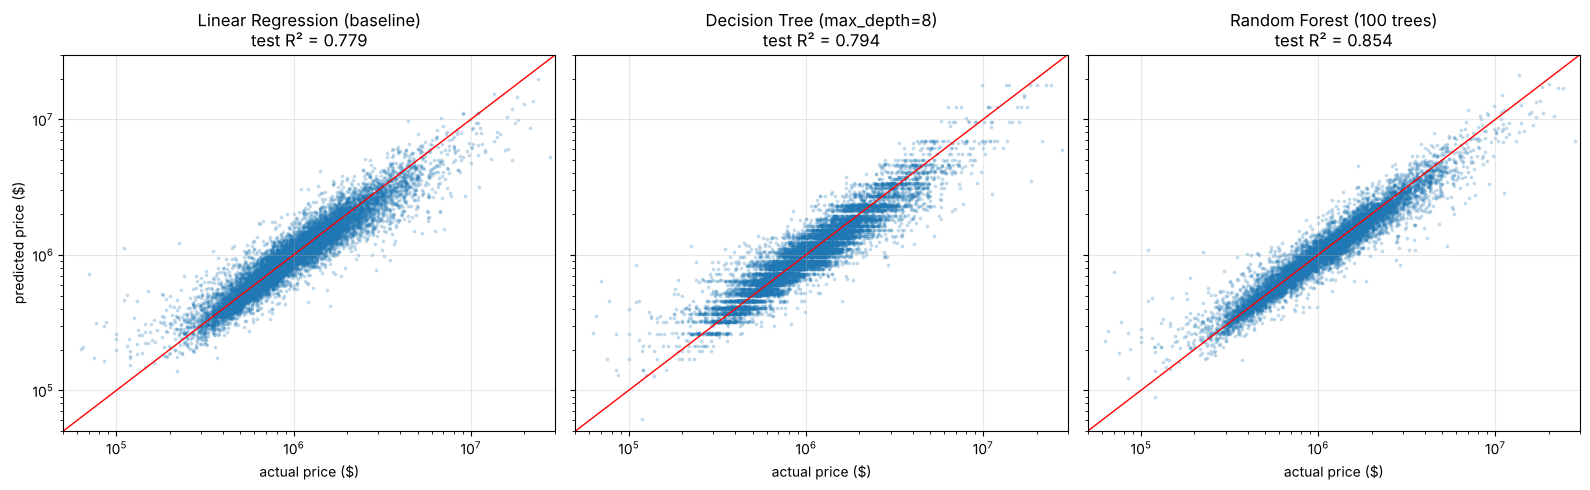

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [5e4, 3e7]
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, s=3, alpha=0.2)
    ax.plot(lims, lims, color="red", lw=1)
    ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="actual price ($)",
           title=f"{name}\ntest R² = {results.loc[name, 'test_R2']:.3f}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("predicted price ($)")
plt.tight_layout(); plt.show()

### Error by price band (median % error)

In [9]:
bands = pd.qcut(y_test, 5, labels=["cheapest 20%", "20–40%", "40–60%", "60–80%", "priciest 20%"])
band_table = pd.DataFrame({name: (np.abs(pred - y_test) / y_test).groupby(bands, observed=True).median()
                           for name, pred in predictions.items()})
band_table.index.name = "price band"
band_table

,Linear Regression (baseline),Decision Tree (max_depth=8),Random Forest (100 trees)
price band,,,
cheapest 20%,0.114,0.123,0.072
20–40%,0.107,0.098,0.060
40–60%,0.101,0.113,0.072
60–80%,0.125,0.135,0.091
priciest 20%,0.172,0.184,0.129


## 5. What drives the Random Forest
Feature importance = how much each feature reduced prediction error across all the forest's splits (sums to 1). County columns are added up into one row so they can be compared as a group.

In [10]:
importance = pd.Series(fitted["Random Forest (100 trees)"].feature_importances_, index=X_train.columns)
is_county = importance.index.str.startswith("CountyOrParish_")
grouped = pd.concat([importance[~is_county], pd.Series({"County (all one-hot columns)": importance[is_county].sum()})])
grouped.sort_values(ascending=False).head(12).to_frame("importance")

,importance
ZipPrice,0.502
LivingArea,0.152
BathroomsTotalInteger,0.113
County (all one-hot columns),0.053
Longitude,0.050
Latitude,0.044
BedroomsTotal,0.026
LotSizeSquareFeet,0.019
YearBuilt,0.019
GarageSpaces,0.007


## 6. Strengths and weaknesses

| | Linear Regression | Decision Tree (depth 8) | Random Forest |
|---|---|---|---|
| **Test R² (May 2026)** | 0.779 | 0.794 | **0.854** |
| **Median % error** | 12.1% | 12.7% | **8.2%** |
| **Train vs test R²** | 0.768 vs 0.779: no overfitting | 0.824 vs 0.794: slight | 0.945 vs 0.854: overfits, but still best on new homes |
| **Fit time** | < 1 s | < 1 s | ~15 s |
| **Strengths** | Fast, stable, every coefficient readable as "% change in price" | Captures bends and interactions (e.g. size matters more in pricey ZIPs) with no scaling needed; easy to draw | Most accurate everywhere; averaging many trees cancels most single-tree noise |
| **Weaknesses** | One straight line in log space; can't bend for luxury or rural homes | Predicts only 256 distinct prices (one per leaf), so it's coarse; very sensitive to depth (no limit → R² 0.70 on new homes) | Slower, larger file, harder to explain one prediction; can't predict above/below prices it saw in training |

**Things worth noticing**
* **The single tree barely beats the baseline,** and on the *typical* home it's actually worse (12.7% vs 12.1% median error). Its R² edge comes from pricing expensive homes a bit better, and R² in dollars weights those heavily. With only 256 possible outputs, everyday homes get rounded to the nearest leaf average.
* **The depth sweep shows overfitting clearly:** training R² climbs to 1.000 with no limit while practice R² falls from 0.789 (depth 8) to 0.700. Depth 8 was picked on April, so May stayed untouched.
* **The forest wins in every price band,** cutting typical error by about a third (e.g. 10.7% → 6.0% for the 20–40% band). Luxury homes are still the hardest (12.9%).
* **ZipPrice alone is about half of the forest's importance,** then living area and bathrooms. Location and size dominate, the same story the linear coefficients told in Week 4.

## Summary
* **Same data, features, split and target as the Week 4 baseline,** so the scores compare directly.
* **Decision Tree:** max_depth tuned on April 2026 → **8**. Test R² **0.794** (+0.015 vs baseline), but a worse median error on typical homes.
* **Random Forest** (100 trees, min_samples_leaf=2, max_features=0.33): test R² **0.854** (+0.075), median error **8.2%**. Best model so far.
* **Next:** Week 6 adds engineered features (age, bed/bath ratio, school districts); Week 7 tries gradient boosting and tunes settings like these.